In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import machine_learning_models as mlm
pd.set_option('display.max_rows', 100)

In [ ]:
df = pd.read_csv(r'C:\Users\mechz\Documents\Jobs_Analysis\job_postings.csv')
X = df.drop(columns=['salary_year_avg'])
predictors = X.columns.to_list()
numerical_columns = ['job_posted_year', 'job_posted_month_sine']
numerical_indices = X.columns.get_indexer(numerical_columns)
X = X.to_numpy()
y = np.where(df['salary_year_avg'] > df['salary_year_avg'].median(), 1, 0)

training_index, testing_index = mlm.train_test_split(X.shape[0], 10000)
X_training = X[training_index]
y_training = y[training_index]
X_testing = X[testing_index]
y_testing = y[testing_index]

for index in numerical_indices:
    mean = np.mean(X_training[:,index])
    std = np.std(X_training[:, index])
    X_training[:,index] = (X_training[:,index] - mean) / std
    X_testing[:,index] = (X_testing[:,index] - mean) / std

print(f'The mean, median, and standard deviation of the salary are {np.mean(df['salary_year_avg']):.3f}, {np.median(df['salary_year_avg']):.3f}, and {np.std(df['salary_year_avg']):.3f} respectively.')

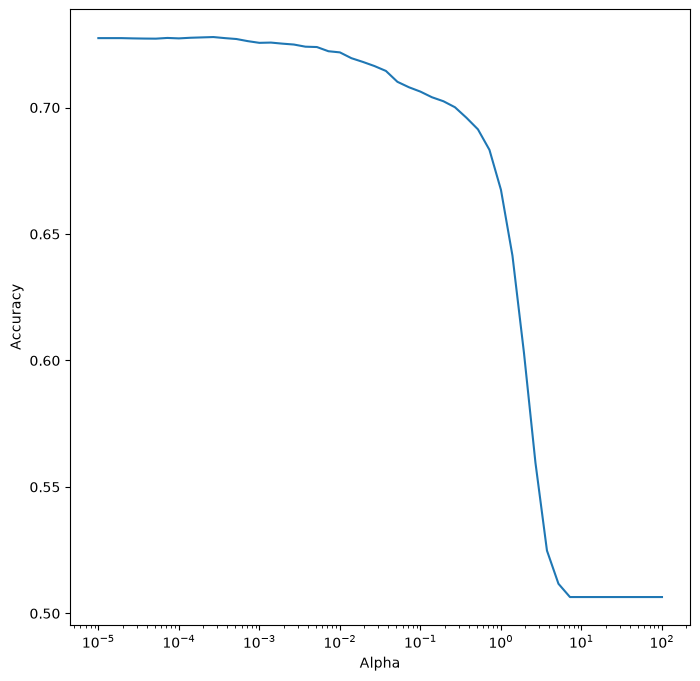

The best alpha value is 0.000 which gives a testing accuracy score of 73.130%.


,value
variable,
job_title_short_Senior Data Scientist,0.771472
job_title_short_Senior Data Engineer,0.690313
job_via_Talent.com,0.467620
job_title_short_Data Scientist,0.464245
job_via_Built In,0.457089
job_via_LinkedIn,0.436726
job_title_short_Software Engineer,0.432241
skills_snowflake,0.350623
skills_python,0.336576


In [ ]:
alphas = np.logspace(-5, 2, 50)
accuracies = {}
for alpha in alphas:
    accuracies_one_fold = []
    for fold in mlm.kfold_cross_validation(5, X_training.shape[0]):
        inner_model = mlm.Logistic_Regression()
        inner_model.fit(np.delete(X_training, fold, axis=0), np.delete(y_training, fold, axis=0), alpha=alpha)
        predictions = inner_model.predict(X_training[fold])
        predictions = np.array([1 if x > 0.5 else 0 for x in predictions])
        accuracy = np.sum(predictions == y_training[fold]) / len(y_training[fold])
        accuracies_one_fold.append(accuracy)
    average_accuracy = np.mean(accuracies_one_fold)
    accuracies.update({alpha:average_accuracy})
best_alpha = max(accuracies, key=accuracies.get)

fig, ax = plt.subplots(figsize=(8,8))
ax.semilogx(accuracies.keys(), accuracies.values())
ax.set_xlabel('Alpha')
ax.set_ylabel('Accuracy')
plt.show()

final_model = mlm.Logistic_Regression(max_iterations=10000, record_losses=True)
final_model.fit(X_training, y_training, alpha=best_alpha)
predictions = final_model.predict(X_testing)
predictions = np.array([1 if x > 0.5 else 0 for x in predictions])
accuracy = np.sum(predictions == y_testing) / len(y_testing)
print(f'The best alpha value is {best_alpha:.3f} which gives a testing accuracy score of {accuracy:.3%}.')

full_model = mlm.Logistic_Regression()
full_model.fit(X, y, alpha=best_alpha)
parameters = ['intercept'] + predictors
parameters_dictionary = dict(zip(parameters, np.insert(full_model.parameters.reshape(-1).copy(), 0, full_model.bias)))
parameters_df = pd.DataFrame([parameters_dictionary])
parameters_df = pd.melt(parameters_df).set_index('variable', drop=True).sort_values(by='value', ascending=False)
display(parameters_df)

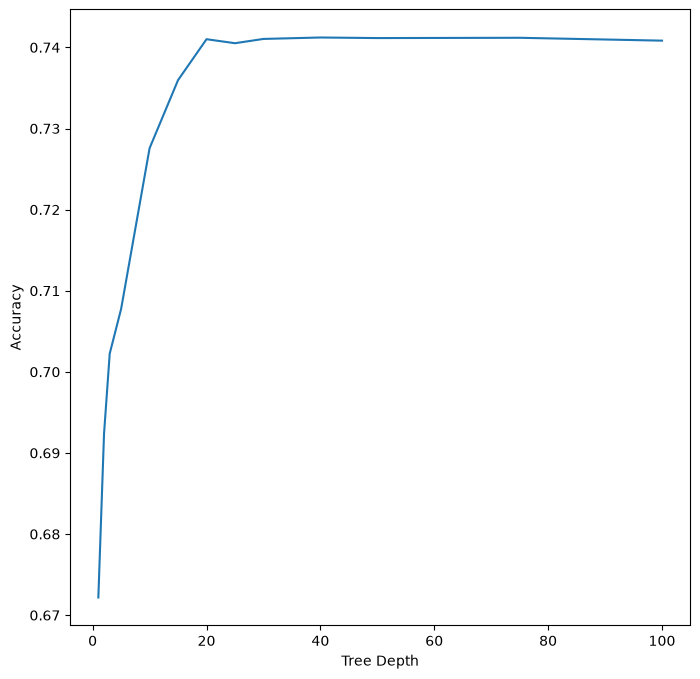

The best tree depth is 40 which gives a testing accuracy score of 0.745.


,permutation_importance,gini_importance,direction
variables,,,
job_title_short_Data Analyst,22.21,0.86,-0.443454
skills_excel,11.45,0.23,-0.200089
job_health_insurance,7.44,1.20,0.107532
skills_python,4.43,4.53,0.051815
skills_spark,4.07,0.58,0.065819
job_posted_year,4.02,3.86,0.037034
job_via_LinkedIn,3.82,0.58,0.092941
job_title_short_Business Analyst,3.37,0.18,-0.316674
job_via_BeBee,2.97,1.36,-0.091075


In [ ]:
depths = [1, 2, 3, 5, 10, 15, 20, 25, 30, 40, 50, 75, 100]
accuracies = []
for depth in depths:
    accuracies_one_fold = []
    for fold in mlm.kfold_cross_validation(5, len(y_training)):
        inner_model = mlm.Classification_Tree(X.shape[1], max_depth=depth)
        inner_model.fit(np.delete(X_training, fold, axis=0), np.delete(y_training, fold))
        predictions = inner_model.predict(X_training[fold])
        accuracy = np.sum(predictions == y_training[fold]) / len(y_training[fold])
        accuracies_one_fold.append(accuracy)
    accuracies.append(np.mean(accuracies_one_fold))
highest_accuracy = max(accuracies)
best_depth = depths[accuracies.index(highest_accuracy)]

fig, ax = plt.subplots(figsize=(8,8))
ax.plot(depths, accuracies)
ax.set_xlabel('Tree Depth')
ax.set_ylabel('Accuracy')
plt.show()

full_model = mlm.Classification_Tree(X.shape[1], max_depth=best_depth)
full_model.fit(X_training, y_training)
predictions = full_model.predict(X_testing)
accuracy = np.sum(predictions == y_testing) / len(y_testing)
print(f'The best tree depth is {best_depth} which gives a testing accuracy score of {accuracy:.3%}.')

parameters = predictors
parameters_dictionary = {'variables':parameters, 'permutation_importance':np.round(full_model.permutation_importances(X_testing, y_testing) * 100, 2), 'gini_importance':np.round(full_model.feature_importances() * 100, 2), 'direction':full_model.direction_of_change()}
parameters_df = pd.DataFrame(parameters_dictionary).sort_values(by='permutation_importance', ascending=False).set_index('variables', drop=True)
display(parameters_df)

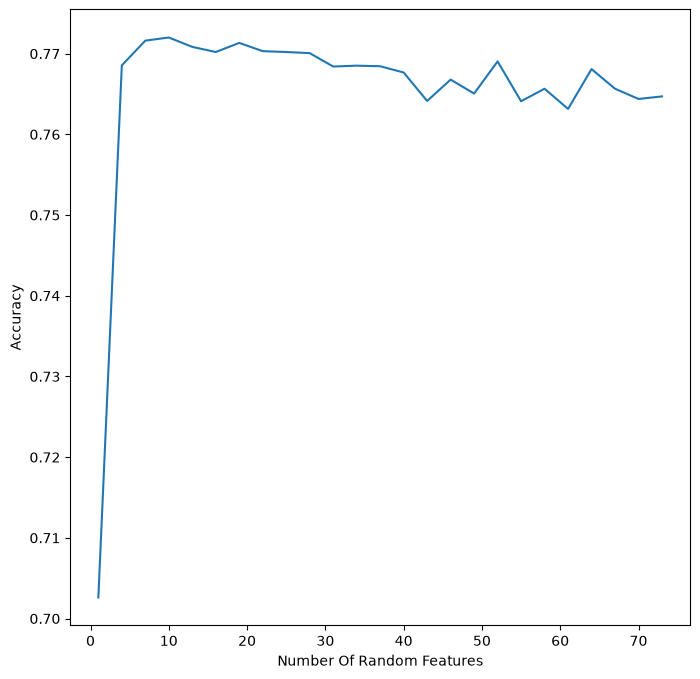

The best number of random features is 10 which gives a testing accuracy of 0.790.


,permutation_importance,gini_importance,direction
variables,,,
job_title_short_Data Analyst,12.96,0.86,-0.274856
skills_excel,6.13,1.11,-0.197595
skills_python,6.12,1.50,0.118081
job_health_insurance,4.55,2.07,0.069420
job_title_short_Data Scientist,4.04,1.24,0.059838
job_title_short_Senior Data Scientist,3.48,0.54,0.195640
skills_spark,3.23,1.38,0.096143
job_title_short_Data Engineer,2.80,1.36,0.030989
skills_aws,2.69,2.15,0.057198


In [ ]:
random_feature_numbers = np.unique(np.linspace(1, X_training.shape[1], 3).astype(np.int32))
accuracies = []
for random_feature_number in random_feature_numbers:
    accuracies_one_fold = []
    for fold in mlm.kfold_cross_validation(3, len(y_training)):
        inner_model = mlm.Classification_Random_Forest(number_of_trees=5, number_of_random_features=random_feature_number)
        inner_model.fit(np.delete(X_training, fold, axis=0), np.delete(y_training, fold, axis=0))
        predictions = inner_model.predict(X_training[fold])
        predictions = np.array([1 if x > 0.5 else 0 for x in predictions])
        accuracy = np.sum(predictions == y_training[fold]) / len(y_training[fold])
        accuracies_one_fold.append(accuracy)
    accuracies.append([np.mean(accuracies_one_fold), random_feature_number])
accuracies = np.array(accuracies)
row_number = np.argmax(accuracies[:, 0])
best_random_feature_number = int(accuracies[row_number, 1])

fig, ax = plt.subplots(figsize=(8,8))
ax.plot(accuracies[:, 1], accuracies[:, 0])
ax.set_xlabel('Number Of Random Features')
ax.set_ylabel('Accuracy')
plt.show()

full_model = mlm.Classification_Random_Forest(number_of_trees=50, number_of_random_features=best_random_feature_number)
full_model.fit(X_training, y_training)
predictions = full_model.predict(X_testing)
predictions = np.array([1 if x > 0.5 else 0 for x in predictions])
accuracy = np.sum(predictions == y_testing) / len(y_testing)
print(f'The best number of random features is {best_random_feature_number} which gives a testing accuracy of {accuracy:.3%}.')

parameters = predictors
parameters_dictionary = {'variables':parameters, 'permutation_importance':np.round(full_model.permutation_importances(X_testing, y_testing) * 100, 2), 'gini_importance':np.round(full_model.feature_importances() * 100, 2), 'direction':full_model.direction_of_change()}
parameters_df = pd.DataFrame(parameters_dictionary).sort_values(by='permutation_importance', ascending=False).set_index('variables', drop=True)
display(parameters_df)

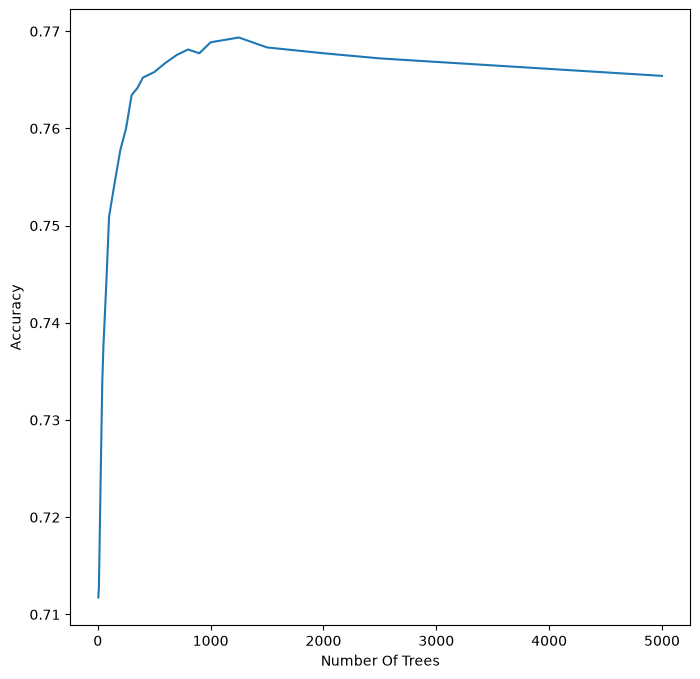

The best number of trees is 1250 which gives a testing accuracy of 0.778.


c:\Users\mechz\Documents\Jobs_Analysis\machine_learning_models.py:202: RuntimeWarning: invalid value encountered in divide
  permutation_importances = permutation_importances / np.sum(permutation_importances)


,permutation_importance,gini_importance,direction
variables,,,
job_work_from_home,NaN,1.20,0.000002
job_no_degree_mention,NaN,0.50,-0.000230
job_health_insurance,NaN,3.22,0.000663
job_posted_year,NaN,1.64,0.001224
job_posted_month_sine,NaN,1.75,0.000008
Contractor,NaN,0.46,-0.000247
Full-time,NaN,0.39,0.000901
Internship,NaN,0.33,-0.002393
Part-time,NaN,0.42,0.000525


In [ ]:
number_of_trees = [5, 10, 20, 30, 40, 50, 75, 100, 150, 200, 250, 300, 350, 400, 500, 600, 700, 800, 900, 1000, 1250, 1500, 2000, 2500, 5000]
accuracies = []
for tree_number in number_of_trees:
    accuracies_one_fold = []
    for fold in mlm.kfold_cross_validation(5, len(y_training)):
        inner_model = mlm.Classification_Gradient_Boosting(number_of_trees=tree_number)
        inner_model.fit(np.delete(X_training, fold, axis=0), np.delete(y_training, fold, axis=0))
        predictions = inner_model.predict(X_training[fold])
        predictions = [1 if x > 0.5 else 0 for x in predictions]
        accuracy = np.sum(y_training[fold] == predictions) / len(y_training[fold])
        accuracies_one_fold.append(accuracy)
    accuracies.append([np.mean(accuracies_one_fold), tree_number])
accuracies = np.array(accuracies)
row_number = np.argmax(accuracies[:, 0])
best_tree_number = int(accuracies[row_number, 1])

fig, ax = plt.subplots(figsize=(8,8))
ax.plot(accuracies[:, 1], accuracies[:, 0])
ax.set_xlabel('Number Of Trees')
ax.set_ylabel('Accuracy')
plt.show()

full_model = mlm.Classification_Gradient_Boosting(number_of_trees=best_tree_number)
full_model.fit(X_training, y_training)
predictions = full_model.predict(X_testing)
predictions = [1 if x > 0.5 else 0 for x in predictions]
accuracy = np.sum(y_testing == predictions) / len(y_testing)
print(f'The best number of trees is {best_tree_number} which gives a testing accuracy of {accuracy:.3%}.')

parameters = predictors
parameters_dictionary = {'variables':parameters, 'permutation_importance':np.round(full_model.permutation_importances(X_testing, y_testing) * 100, 2), 'gini_importance':np.round(full_model.feature_importances() * 100, 2), 'direction':full_model.direction_of_change()}
parameters_df = pd.DataFrame(parameters_dictionary).sort_values(by='permutation_importance', ascending=False).set_index('variables', drop=True)
display(parameters_df)

In [4]:
hidden_layer_numbers = [1, 3, 5, 10, 20]
hidden_sizes = [3, 5, 10, 20, 50]
accuracies = np.zeros((len(hidden_layer_numbers), len(hidden_sizes)))

for i, hidden_layer_number in enumerate(hidden_layer_numbers):
    for j, hidden_size in enumerate(hidden_sizes):
        accuracies_one_fold = []
        for fold in mlm.kfold_cross_validation(5, len(y_training)):
            inner_model = mlm.Classification_Neural_Network(hidden_layer_number, hidden_size, epochs=1000)
            inner_model.fit(np.delete(X_training, fold, axis=0), np.delete(y_training, fold, axis=0))
            predictions = inner_model.predict(X_training[fold])
            predictions = np.array([1 if x > 0.5 else 0 for x in predictions])
            accuracy = np.sum(predictions == y_training[fold]) / len(y_training[fold])
            accuracies_one_fold.append(accuracy)
        accuracies[i, j] = np.mean(accuracies_one_fold)
best_coords = np.argmax(accuracies)
best_coords = np.unravel_index(best_coords, accuracies.shape)
best_hidden_layer_number = hidden_layer_numbers[best_coords[0]]
best_hidden_size = hidden_sizes[best_coords[1]]

fig, ax = plt.subplots(figsize=(8, 8))
plot = ax.contour(hidden_layer_numbers, hidden_sizes, accuracies)
ax.set_xlabel('Number Of Hidden Layers')
ax.set_ylabel('Hidden Layer Size')
plt.plot(best_hidden_layer_number, best_hidden_size, marker='o', markersize=10, color='red')
plot.clabel()
plt.show()

final_model = mlm.Classification_Neural_Network(best_hidden_layer_number, best_hidden_size, epochs=10000)
final_model.fit(X_training, y_training)
predictions = final_model.predict(X_testing)
predictions = np.array([1 if x > 0.5 else 0 for x in predictions])
accuracy = np.sum(predictions == y_testing) / len(y_testing)
r2 = 1 - (np.sum((y_testing - predictions)**2)) / (np.sum((y_testing - np.mean(y_testing))**2))
print(f'The best number of hidden layers is {best_hidden_layer_number} and the best hidden layer size is {best_hidden_size} giving a testing accuracy of {accuracy:.3%}.')

parameters = predictors
parameters_dictionary = {'variables':parameters, 'permutation_importance':np.round(final_model.permutation_importances(X_testing, y_testing) * 100, 2)}
parameters_df = pd.DataFrame(parameters_dictionary).sort_values(by='permutation_importance', ascending=False).set_index('variables', drop=True)
display(parameters_df)

KeyboardInterrupt: 